In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("HW_1b_numpy_and_plotting.ipynb")

# HW 1b: Statistical analysis of data using numpy and matplotlib

Slides: (https://docs.google.com/presentation/d/1ef0msC9XIT37_Yg94Cf4TL9VBgbIIfkKik8jgshskjE/edit?usp=sharing)

Please do Homework 1a before starting this assignment.

In this homework you will focus on analysis - categorizing the type of a given motion (snap, high five, or clap) and determined its accuracy on the provided dataset.

## Getting started

GUIDE: From HW 1b, copy the library imports, data load, and the functions. 

Everything here should be a direct copy from HW1. Each JN cell has a comment for what should be copied into that cell. Do not just copy everything over into one cell.

In [2]:
# GUIDE: Do the imports here
import numpy as np
import json as json

import os

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# GUIDE: Load the data set
full_dataset = np.loadtxt("Data/full_dataset.csv", delimiter=',')
with open("Data/full_dataset_data_description.json", "r") as fp:
        data_description = json.load(fp)

# Numeric ids to indicate hand motion type from Lab 1
clap_id = 1
high_five_id = 2
snap_id = 3

# Hardcoded column numbers for this data to make the code easier; normally, you would extract this from
# full_dataset_data_description.json.
timestamp_col = 0
subject_number_col = 13
run_number_col = 14
motion_id_col = 15

In [4]:
# GUIDE: The function for getting the channel data, given the data, the offset, and the dimensions
def get_channel_data(all_data, index_offset, n_dims):
    """ Get the data for just one channel (e.g., right hand accelerometer)
    @param all_data - numpy array containing data from one (or more) files
    @param index_offset - the column to begin getting data from
    @param n_dims - number of dimensions for the data channel
    @return Returned array should be: number of rows in all_data X n_dims"""

    channel_data = all_data[:, index_offset: index_offset + n_dims]
    return channel_data

In [5]:
# GUIDE: The function for getting the descriptor for the data channel, given the name
def get_descriptor(data_description, name):
    """ Search through data_description to find the dictionary with name "name"
    @param name - The name of the data channel to look for. 
    @return the dictionary that has name as the 'name' key"""
    
    list_of_dict = data_description["data_channels"]
    for item in list_of_dict:
        if item["name"] == name:
            return item
        else:
            pass

In [6]:
# GUIDE: The function for getting the root mean square error
def rms(in_data):
   """ Calculate the root mean square of each row in in_data.
   @param in_data - A 2-dimensional numpy array
   @return An n rows by 1 column numpy array containing the RMS of each row in in_data.
   """
   # GUIDES: Fill in this function.
   # Hint: Use numpy functions to operate on the entire array at once rather than
   # iterate through each row.
   return np.sqrt(np.mean(in_data**2, axis=1, keepdims=True))

In [7]:
# GUIDE: The function for pulling out just the given subject number, run number, and motion id from the full data set
def filter_data_set(data, subject_number, run_number, motion_id):
    """ Filters a data set to a specific run of a specific motion type from a specific subject.
    @param data - The full dataset, containing multiple motion runs from multiple people.
    @return Just the rows for the given subject number, run number, and motion id.
    """
    refined_rows = (
    (data[:, subject_number_col] == subject_number) 
    & (data[:, motion_id_col] == motion_id) 
    & (data[:, run_number_col] == run_number)
    )
    s3s4_snap_data = data[refined_rows]
    return s3s4_snap_data

In [8]:
# GUIDE: The function for pulling out the row index that has the given value from the data
def find_row_with_value(data, value):
    """ Locates the first index of data containing value.
    @param data - A 1-d array containing data.
    @param value - A specific value to look for in data.
    @return The index of value within data, or -1 if value is not found.
    """
    # GUIDES: Write this function. See the optional section of lab 2 for hints on how to do this.
    b_is_value = data == value
    indices = np.where(b_is_value)
    if len(indices) == 0:
        return -1
    return indices[0][0]

In [9]:
# Add some tests to make sure your functions/data loading are correct
test_array = np.array([[1, 2, 3], [4, 5, 6]])
test_array_rms = rms(test_array)
assert(np.isclose(test_array_rms[1], 5.06622805))

find_row_with_value_test_array = np.array([6, 7, 8, 7, 5])
assert(find_row_with_value(find_row_with_value_test_array, 5) == 4)

In [10]:
grader.check("copy_code")

copy_code results: All test cases passed!

## Problem 1: Graph RMS for each motion type

You did a basic plot in homework 1a. In this problem, you will adjust the y axis of all of the plots so that it will be easier to compare min/max values across different subjects/motions.

GUIDE
- Copy the plot function over.
- Determine a good y axis maximum value for each motion type by plotting a bunch of them
- Change the plot function so that all motions plot with the same y axis values

This question has a manually-graded portion; if your plots are incorrect you will have points deducted on Gradescope. See slides for what the plots should look like.

In [11]:
# GUIDE: 
# Step 1: Copy the plot function from the previous homework 
# Step 2: Add a parameter that specifies the height of the y axis
# Step 3: Use that parameter to set the y axis (search matplotlib set y axis range)

def plot_function(axs, ts, data, y_height, channel_info, dim_name):
    """ Plot all of the dimensions for a given channel
    @param axs - the place to plot in
    @param ts - the time steps to use
    @param data - the numpy array from the csv file
    @param channel_info - a dictionary with the channel info, e.g. "name" and "units"
    @param dim_name - the name of the dimension being called
    @returns - nothing"""

    axs.plot(ts, data)
    axs.set_title(channel_info[dim_name]['name'])
    axs.set_xlabel(channel_info['Timestamp']['units'])
    axs.set_ylabel(channel_info[dim_name]['units'])
    axs.set_ylim(0, y_height)
    pass

In [12]:
# GUIDE: Copy the code that gets the RMS of the accelerometera data for the left and right hand of subject 6

snap_subject_number = 6
snap_run_number = 3

clap_subject_number = 6
clap_run_number = 3

high_five_subject_number = 6
high_five_run_number = 3

In [13]:
channel_info = {
    "Timestamp": {
        "units": "Seconds"
    },
    "Left hand snap rms": {
        "name": "Snap (LH)",
        "units": "gravity units",
    },
    "Right hand snap rms": {
        "name": "Snap (RH)",
        "units": "gravity units"
    },
    "Left hand clap rms": {
        "name": "Clap (LH)",
        "units": "gravity units"
    },
    "Right hand clap rms": {
        "name": "Clap (RH)",
        "units": "gravity units"
    },
    "Left hand high five rms": {
        "name": "High Five (LH)",
        "units": "gravity units"
    },
    "Right hand high five rms": {
        "name": "High Five (RH)",
        "units": "gravity units"
    },
}

In [14]:
all_data = np.copy(full_dataset)

ts_descriptor = get_descriptor(data_description, "Timestamp")

filtered_snap_data = filter_data_set(all_data, snap_subject_number, snap_run_number, snap_id)
ts_snap = get_channel_data(filtered_snap_data, index_offset=ts_descriptor["index_offset"], n_dims=ts_descriptor["dimensions"])
filtered_clap_data = filter_data_set(all_data, clap_subject_number, clap_run_number, clap_id)
ts_clap = get_channel_data(filtered_clap_data, index_offset=ts_descriptor["index_offset"], n_dims=ts_descriptor["dimensions"])
filtered_high_five_data = filter_data_set(all_data, high_five_subject_number, high_five_run_number, high_five_id)
ts_high_five = get_channel_data(filtered_high_five_data, index_offset=ts_descriptor["index_offset"], n_dims=ts_descriptor["dimensions"])


lh_accelerometer_descriptor = get_descriptor(data_description, "Left hand accelerometer")
lh_accelerometer_snap_data = get_channel_data(filtered_snap_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_snap_rms_data = rms(lh_accelerometer_snap_data)
lh_accelerometer_clap_data = get_channel_data(filtered_clap_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_clap_rms_data = rms(lh_accelerometer_clap_data)
lh_accelerometer_high_five_data = get_channel_data(filtered_high_five_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_high_five_rms_data = rms(lh_accelerometer_high_five_data)

rh_accelerometer_descriptor = get_descriptor(data_description, "Right hand accelerometer")
rh_accelerometer_snap_data = get_channel_data(filtered_snap_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_snap_rms_data = rms(rh_accelerometer_snap_data)
rh_accelerometer_clap_data = get_channel_data(filtered_clap_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_clap_rms_data = rms(rh_accelerometer_clap_data)
rh_accelerometer_high_five_data = get_channel_data(filtered_high_five_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_high_five_rms_data = rms(rh_accelerometer_high_five_data)

[]

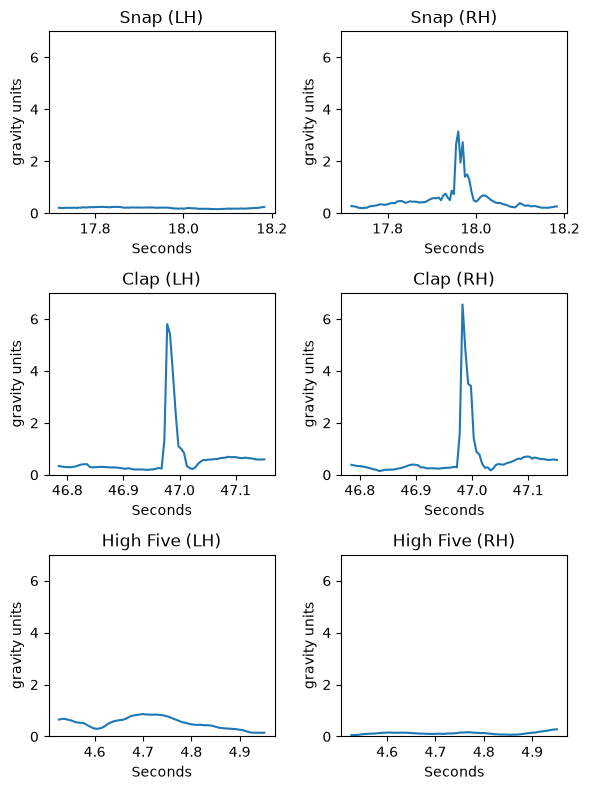

In [15]:
# GUIDE: Make the same plot as from homework 1, for subject 6 run number 3 - but set the y limit to something reasonable
#. so that you can see the plots but they all have the same y axis limits
# Plot size
nrows = 3
ncols = 2
fig, axs = plt.subplots(nrows, ncols, figsize=(6, 8))

y_lim = 7
plot_function(axs=axs[0,0], ts=ts_snap/1000, data=lh_snap_rms_data, y_height=y_lim, channel_info=channel_info, dim_name='Left hand snap rms')
plot_function(axs=axs[0,1], ts=ts_snap/1000, data=rh_snap_rms_data, y_height=y_lim, channel_info=channel_info, dim_name='Right hand snap rms')
plot_function(axs=axs[1,0], ts=ts_clap/1000, data=lh_clap_rms_data, y_height=y_lim, channel_info=channel_info, dim_name='Left hand clap rms')
plot_function(axs=axs[1,1], ts=ts_clap/1000, data=rh_clap_rms_data, y_height=y_lim, channel_info=channel_info, dim_name='Right hand clap rms')
plot_function(axs=axs[2,0], ts=ts_high_five/1000, data=lh_high_five_rms_data, y_height=y_lim, channel_info=channel_info, dim_name='Left hand high five rms')
plot_function(axs=axs[2,1], ts=ts_high_five/1000, data=rh_high_five_rms_data, y_height=y_lim, channel_info=channel_info, dim_name='Right hand high five rms')

fig.tight_layout()
plt.plot()

In [16]:
grader.check("graph_rms")

graph_rms results: All test cases passed!

## Determine motion type from data

Observe your graphs from the previous problem. How can you tell, from these graphs alone, what motion type the subject is performing?

Some helpful context:

* Subjects were told to snap with their _right hand_ and high five with their _left hand_.
* The high five was pantomimed; that is, the subject did not make contact with another hand, but instead made a high five motion.

From your observations, write a function that takes in the left hand and right hand accelerometer RMS values and returns the most likely motion type that the subject is performing.

Hint: Look at the peaks in the graphs, the magnitude of the peaks, and the hand(s) that the peaks occur on.

Hint: You could return to the previous problem and graph different subjects/runs for inspiration.

In [17]:
# GUIDES: Put any additional functions you want here

# NOTES FOR CREATING FUNCTION
# We'll consider the motion to be a SNAP if the max rh_accelerometer_rms is less than 4 but greater than 2
# We'll consider the motion to be a CLAP if the max rh_accelerometer_rms is greater than 4
# We'll consider the motion to be a HIGH FIVE if the max rh_accelerometer_rms is les than 2 

In [18]:
# GUIDES: Write a function that analyzes the data and returns the id of the one
#  it guesses
def guess_motion_type(lh_accelerometer_rms, rh_accelerometer_rms):
    """ Guesses the motion that the subject is performing given the RMS of the user's left hand and right hand accelerometers.
    @param lh_accelerometer_rms - RMS of the left hand accelerometer
    @param rh_accelerometer_rms - RMS of the right hand accelerometer
    @return The motion ID of the motion the user was most likely performing.
    """

    if (2 < np.max(rh_accelerometer_rms) < 4) & (2 > np.max(lh_accelerometer_rms)):
        return snap_id
    elif (4 < np.max(rh_accelerometer_rms)) & (4 < np.max(lh_accelerometer_rms)):
        return clap_id
    else: 
        if (2 > np.max(rh_accelerometer_rms)) & (2 > np.max(lh_accelerometer_rms)):
            return high_five_id


In [19]:
# GUIDES: Write some tests here to check that you have the "right" answer
#  i.e., if you give it snap data it should return snap (for at least some of the snap data)
assert(snap_id == guess_motion_type(lh_snap_rms_data, rh_snap_rms_data))
assert(clap_id == guess_motion_type(lh_clap_rms_data, rh_clap_rms_data))
assert(high_five_id == guess_motion_type(lh_high_five_rms_data, rh_high_five_rms_data))



In [20]:
# GUIDE: get the s3 s4 snap data (from homework 1a)
s3s4_snap_data = filter_data_set(data=all_data, subject_number=snap_subject_number, run_number=snap_run_number, motion_id=snap_id)
lh_accelerometer_descriptor = get_descriptor(data_description, "Left hand accelerometer")
s3s4_snap_lh_accelerometer_data = get_channel_data(s3s4_snap_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
rh_accelerometer_descriptor = get_descriptor(data_description, "Right hand accelerometer")
s3s4_snap_rh_accelerometer_data = get_channel_data(s3s4_snap_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])

assert(snap_id == guess_motion_type(rms(s3s4_snap_lh_accelerometer_data), rms(s3s4_snap_rh_accelerometer_data)))

In [21]:
grader.check("determine_motion_type")

determine_motion_type results: All test cases passed!

## Calculate accuracy of your heuristic

You now have a function that guesses the motion type for a given motion, and we have ground truth labels for what motions the subjects are performing. Let's calculate the accuracy of your heuristic using this function!

The data set contains 10 subjects (1 through 10) that perform 10 runs (1 through 10) of each motion type (snap, high five, and clap). You can use three nested for loops (one for participant number, one for run number, one for motion ID) to iterate through each of the motion observations and guess the motion type.

We expect to see accuracies above 75%, and accuracies above 90% are possible.

In [22]:
# GUIDES: Produce a numpy array that contains a row with 4 columns containing subject number, run number, actual motion, and guessed motion
accuracy_info = np.zeros((300, 4))
row_num = 0
# GUIDES: Count the number of correct and incorrect guesses.
# Hint: np.where is useful here.
for subject in range(1,11):
    for run in range(1,11):
        for motion in range(1,4):
            lh_filtered_data = filter_data_set(data=full_dataset, subject_number=subject, run_number=run, motion_id=motion)
            rh_filtered_data = filter_data_set(data=full_dataset, subject_number=subject, run_number=run, motion_id=motion)
            lh_rms = rms(get_channel_data(lh_filtered_data, lh_accelerometer_descriptor["index_offset"], lh_accelerometer_descriptor["dimensions"]))
            rh_rms = rms(get_channel_data(rh_filtered_data, rh_accelerometer_descriptor["index_offset"], rh_accelerometer_descriptor["dimensions"]))
            motion_guess = guess_motion_type(lh_rms, rh_rms)
            accuracy_info[row_num] = [subject, run, motion, motion_guess]
            row_num += 1

correct_count = 0
incorrect_count = 0 
for row in accuracy_info:
    if row[2] == row[3]:
        correct_count += 1
    else:
        incorrect_count += 1

# GUIDES: Use correct_count and incorrect_count to calculate accuracy
# Hint: You will need to do conversions to floats to avoid doing integer division.
accuracy = correct_count / (incorrect_count + correct_count)

print(f'guess_motion_type is {accuracy * 100}% accurate')

guess_motion_type is 81.0% accurate


In [23]:
grader.check("calculate_accuracy")

calculate_accuracy results: All test cases passed!

## Find the "worst" subject

Which subject does your heuristic perform the worst on?

In [24]:
# GUIDES: Populate a numpy array with one entry per subject, counting the number of 
# incorrect motion type predictions.
incorrect_by_subject = np.zeros(10)

# GUIDES: Use incorrect_by_subject to determine the subject number that guess_motion_type
# performed worst on.
# Hint: find_row_with_value might be useful here.
for i, subject in enumerate(range(1,11)):
    row_indicator = accuracy_info[:, 0] == subject
    subject_row = accuracy_info[row_indicator]
    wrong_guesses = subject_row[:, 2] != subject_row[:, 3]
    incorrect_by_subject[i] = np.sum(wrong_guesses)
max_wrong = np.max(incorrect_by_subject)
worst_subject_index = find_row_with_value(incorrect_by_subject, max_wrong)
worst_subject_number = worst_subject_index + 1

print(f'guess_motion_type performed worst on subject {worst_subject_number}')

guess_motion_type performed worst on subject 7


In [25]:
grader.check("worst_subject")

worst_subject results: All test cases passed!

## Hours and collaborators
Required for every assignment - fill out before you hand-in.

Listing names and websites helps you to document who you worked with and what internet help you received in the case of any plagiarism issues. You should list names of anyone (in class or not) who has substantially helped you with an assignment - or anyone you have *helped*. You do not need to list TAs.

Listing hours helps us track if the assignments are too long.

In [26]:
import os

# List of names (creates a set)
worked_with_names = {"By Myself"}
# List of URLS FA26 (creates a set)
websites = {"geeksforgeeks.org/python/how-to-set-axis-ranges-in-matplotlib/"
            "https://www.w3schools.com/python/ref_func_enumerate.asp"}
# Approximate number of hours, including lab/in-class time
hours = 10

# VS Code stores the path in a special global variable
if '__vsc_ipynb_file__' in globals():
    notebook_path = globals()['__vsc_ipynb_file__']
    notebook_name = os.path.basename(notebook_path)
    json_name = notebook_name[:-6] + "_source.json"
    if not os.path.exists(json_name):
        print(f"Could not find the json file {json_name}; make sure the required VSCode extension is installed and running")


In [27]:
grader.check("hours_collaborators")

hours_collaborators results: All test cases passed!

### To submit

- Do a restart then run all to make sure everything runs ok
- Remove excessive print statements - don't make us search through pages of numbers to find your plots
- Save the file
- Submit this .ipynb file, along with the .json file, through gradescope, HWK1 numpy and Plotting
- You do NOT need to submit the data files - we will supply those

If the Gradescope autograder fails, please check here first for common reasons for it to fail
    https://docs.google.com/presentation/d/1tYa5oycUiG4YhXUq5vHvPOpWJ4k_xUPp2rUNIL7Q9RI/edit?usp=sharing

Most likely failure for this assignment is not naming the data directory and files correctly; capitalization matters for the Gradescope grader. 